# 01 · Dataset exploration (EDA)
**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The evaluator partition is never read.

This notebook calls `scripts/01_eda.py`, which runs the full analysis, then shows its outputs and adds a few interactive views.

In [1]:
import os, sys, json, time, warnings
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src")); sys.path.insert(0, os.path.join(ROOT, "scripts"))
os.chdir(os.path.join(ROOT, "scripts"))  # scripts use paths relative to the repo
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, IFrame, HTML
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
DATA, RES, FIG = os.path.join(ROOT, "data"), os.path.join(ROOT, "results"), os.path.join(ROOT, "results", "figures")

## 1. Raw files of one trip
The files have no headers. `.track` = lon, lat, t(s) · `.nodes` = lon, lat (row = node id) · `.arcs` = from, to (row = arc id) · `.route` = ordered arc ids.

In [2]:
tid = "00000048"; d = f"{DATA}/train/{tid}"
for ext in ["track", "nodes", "arcs", "route"]:
    df = pd.read_csv(f"{d}/{tid}.{ext}", sep=r"\s+", header=None)
    print(f".{ext:6s} rows={len(df):6d} cols={df.shape[1]}  dtypes={list(df.dtypes.astype(str))}")
    display(df.head(3))

.track  rows=  1240 cols=3  dtypes=['float64', 'float64', 'float64']


,0,1,2
0,-1.859609,52.964840,1.0
1,-1.859689,52.964783,2.0
2,-1.859719,52.964715,3.0


.nodes  rows=  1308 cols=2  dtypes=['float64', 'float64']


,0,1
0,-1.844655,52.951092
1,-1.846513,52.949196
2,-1.848038,52.947605


.arcs   rows=  2592 cols=2  dtypes=['int64', 'int64']


,0,1
0,0,38
1,0,1291
2,1,472


.route  rows=   149 cols=1  dtypes=['int64']


,0
0,571
1,569
2,747


## 2. Run the EDA script (inventory, data quality, network connectivity, plots)

In [3]:
import subprocess
r = subprocess.run([sys.executable, "01_eda.py"], capture_output=True, text=True); print(r.stdout[-3000:], r.stderr[-2000:])

partition         student_test          train
trips                10.000000      80.000000
gps_total         19160.000000  208417.000000
gps_mean           1916.000000    2605.212500
gps_min             262.000000     361.000000
gps_max            3958.000000   19313.000000
nan_rows              0.000000       0.000000
dup_timestamps        0.000000       0.000000
gaps_gt5s            44.000000    1216.000000
nodes_mean         9068.900000   24168.562500
arcs_mean         18504.100000   48461.300000
isolated_nodes        0.000000       0.000000
route_contiguous      0.999732       0.999346
{'anomalous_trips': ['00000033', '00000054'], 'frac_dt_eq_1': 0.9667981027487285, 'frac_dt_eq_2': 0.019609911775178363, 'frac_dt_gt_5': 0.0055387780400638275, 'max_dt': 153064.0, 'label_dist_median_all': 5.644859282242741, 'label_dist_p95_all': 139.0384586131937, 'candidate_miss_train': 0.11216455471482656, 'candidate_miss_train_excl_anom': 0.011759249154207119, 'candidate_miss_student_test': 0.0041

## 3. Dataset inventory and summary

In [4]:
inv = pd.read_csv(f"{RES}/eda_inventory.csv", dtype={"trip": str})
display(pd.read_csv(f"{RES}/eda_summary.csv").set_index("partition").T)
display(inv.head(10))

partition,student_test,train
trips,10.000000,80.000000
gps_total,19160.000000,208417.000000
gps_mean,1916.000000,2605.212500
gps_min,262.000000,361.000000
gps_max,3958.000000,19313.000000
nan_rows,0.000000,0.000000
dup_timestamps,0.000000,0.000000
gaps_gt5s,44.000000,1216.000000
nodes_mean,9068.900000,24168.562500
arcs_mean,18504.100000,48461.300000


,partition,trip,n_gps,n_nan,n_dup_t,n_backwards_t,dt_median,dt_max,frac_dt_1,n_gaps_gt5s,duration_s,path_len_km,max_step_m,lon_min,lon_max,lat_min,lat_max,n_nodes,n_arcs,isolated_nodes,weak_components,largest_weak_frac,strong_components,largest_strong_frac,median_arc_len_m,route_len,route_unique,route_contiguous_frac,file_kb_track
0,train,00000001,1315,0,0,0,1.0,16.0,0.980974,1,1357.000,50.228561,72.444519,8.570524,8.647860,49.844053,50.211882,88809,165790,0,175,0.977986,1942,0.957099,20.234842,525,525,1.000000,40.014648
1,train,00000002,7243,0,0,0,1.0,160.0,0.974455,78,8933.156,55.950971,37.381828,10.999961,11.050902,47.658344,47.695459,7936,16139,0,14,0.976562,14,0.976562,16.064846,262,262,0.996169,232.504883
2,train,00000003,821,0,0,0,1.0,2.0,0.996341,0,823.000,8.439392,29.219252,37.154202,37.201595,55.977135,56.007585,9138,18028,0,42,0.943861,167,0.901182,17.320413,79,79,1.000000,25.550781
3,train,00000004,1064,0,0,0,1.0,51.0,0.538100,320,5217.000,27.945597,139.690233,12.342280,12.459615,52.590308,52.718960,7350,15499,0,12,0.986939,14,0.986667,35.091228,320,320,1.000000,34.162109
4,train,00000005,1045,0,0,0,1.0,1.0,1.000000,0,1044.000,31.346426,63.858196,35.485577,35.544315,49.357581,49.613085,898,1579,0,3,0.988864,153,0.635857,85.137409,105,105,1.000000,32.595703
5,train,00000006,1450,0,0,0,1.0,301.0,0.991718,9,2102.000,19.434428,46.765693,37.276002,37.317675,55.429164,55.487229,3259,6757,0,8,0.903038,8,0.903038,30.468274,261,261,1.000000,46.460938
6,train,00000008,3093,0,0,0,1.0,2.0,0.999677,0,3093.000,25.042567,70.058171,-86.584860,-86.567487,34.733275,34.753704,4995,10421,0,13,0.983584,209,0.938539,24.503141,173,172,1.000000,101.616211
7,train,00000010,2711,0,0,0,1.0,1.0,1.000000,0,2710.000,25.875987,39.362968,37.357893,37.394790,55.786261,55.832857,8502,15715,0,28,0.934016,411,0.855328,20.323420,210,210,1.000000,86.285156
8,train,00000011,2828,0,0,0,1.0,909.0,0.999646,1,3735.000,55.131514,50.396977,59.647057,60.016866,56.041788,56.067535,2649,5393,0,2,0.996980,2,0.996980,22.769211,565,565,1.000000,90.055664
9,train,00000012,1608,0,0,0,1.0,2.0,0.999378,0,1608.000,41.611968,55.334522,44.044515,44.389906,36.175914,36.263587,16376,38599,0,22,0.982413,165,0.910723,44.425191,205,205,1.000000,50.742188


## 4. Missing values, sampling irregularities, anomalies

In [5]:
facts = json.load(open(f"{RES}/eda_facts.json")); display(pd.Series(facts))
print("Trips with the most >5 s gaps:"); display(inv.sort_values("n_gaps_gt5s", ascending=False)[["partition","trip","n_gps","n_gaps_gt5s","dt_max"]].head(5))
lab = pd.read_csv(f"{RES}/eda_label_alignment.csv", dtype={"trip": str})
print("Trips whose GPS sits far from the reference route (systematic offset):"); display(lab.sort_values("label_dist_median", ascending=False).head(5))

anomalous_trips                   [00000033, 00000054]
frac_dt_eq_1                                  0.966798
frac_dt_eq_2                                   0.01961
frac_dt_gt_5                                  0.005539
max_dt                                        153064.0
label_dist_median_all                         5.644859
label_dist_p95_all                          139.038459
candidate_miss_train                          0.112165
candidate_miss_train_excl_anom                0.011759
candidate_miss_student_test                   0.004123
nearest_arc_top1_student_test                 0.532411
dtype: object

Trips with the most >5 s gaps:


,partition,trip,n_gps,n_gaps_gt5s,dt_max
3,train,00000004,1064,320,51.0
64,train,00000081,3224,129,536.0
61,train,00000078,2909,124,52810.0
17,train,00000022,474,87,22.0
1,train,00000002,7243,78,160.0


Trips whose GPS sits far from the reference route (systematic offset):


,part,trip,label_dist_median,label_dist_p95,candidate_miss
54,train,00000054,140.116231,210.093911,0.895770
36,train,00000033,122.421322,142.068025,0.671116
45,train,00000043,11.013724,70.233169,0.067614
13,train,00000004,8.519377,29.504142,0.014098
16,train,00000008,7.795555,28.212835,0.013902


## 5. Plots

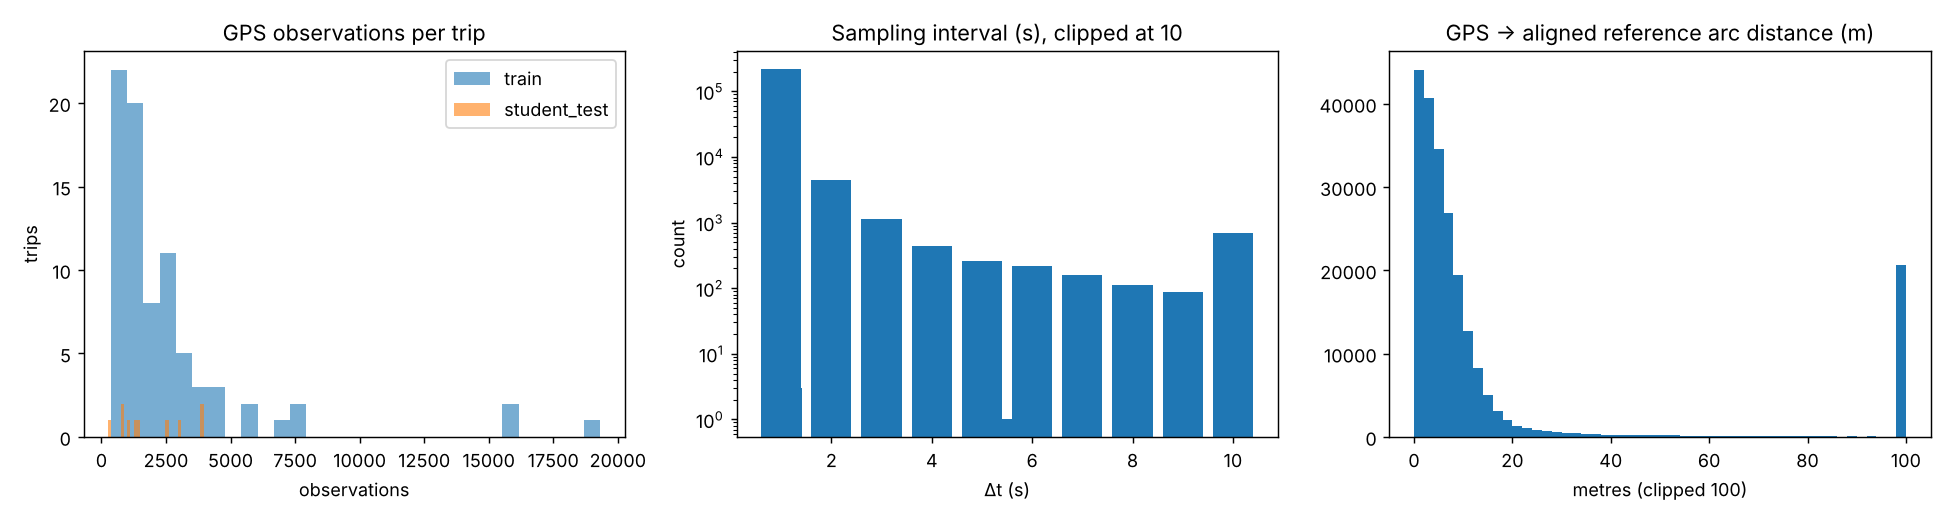

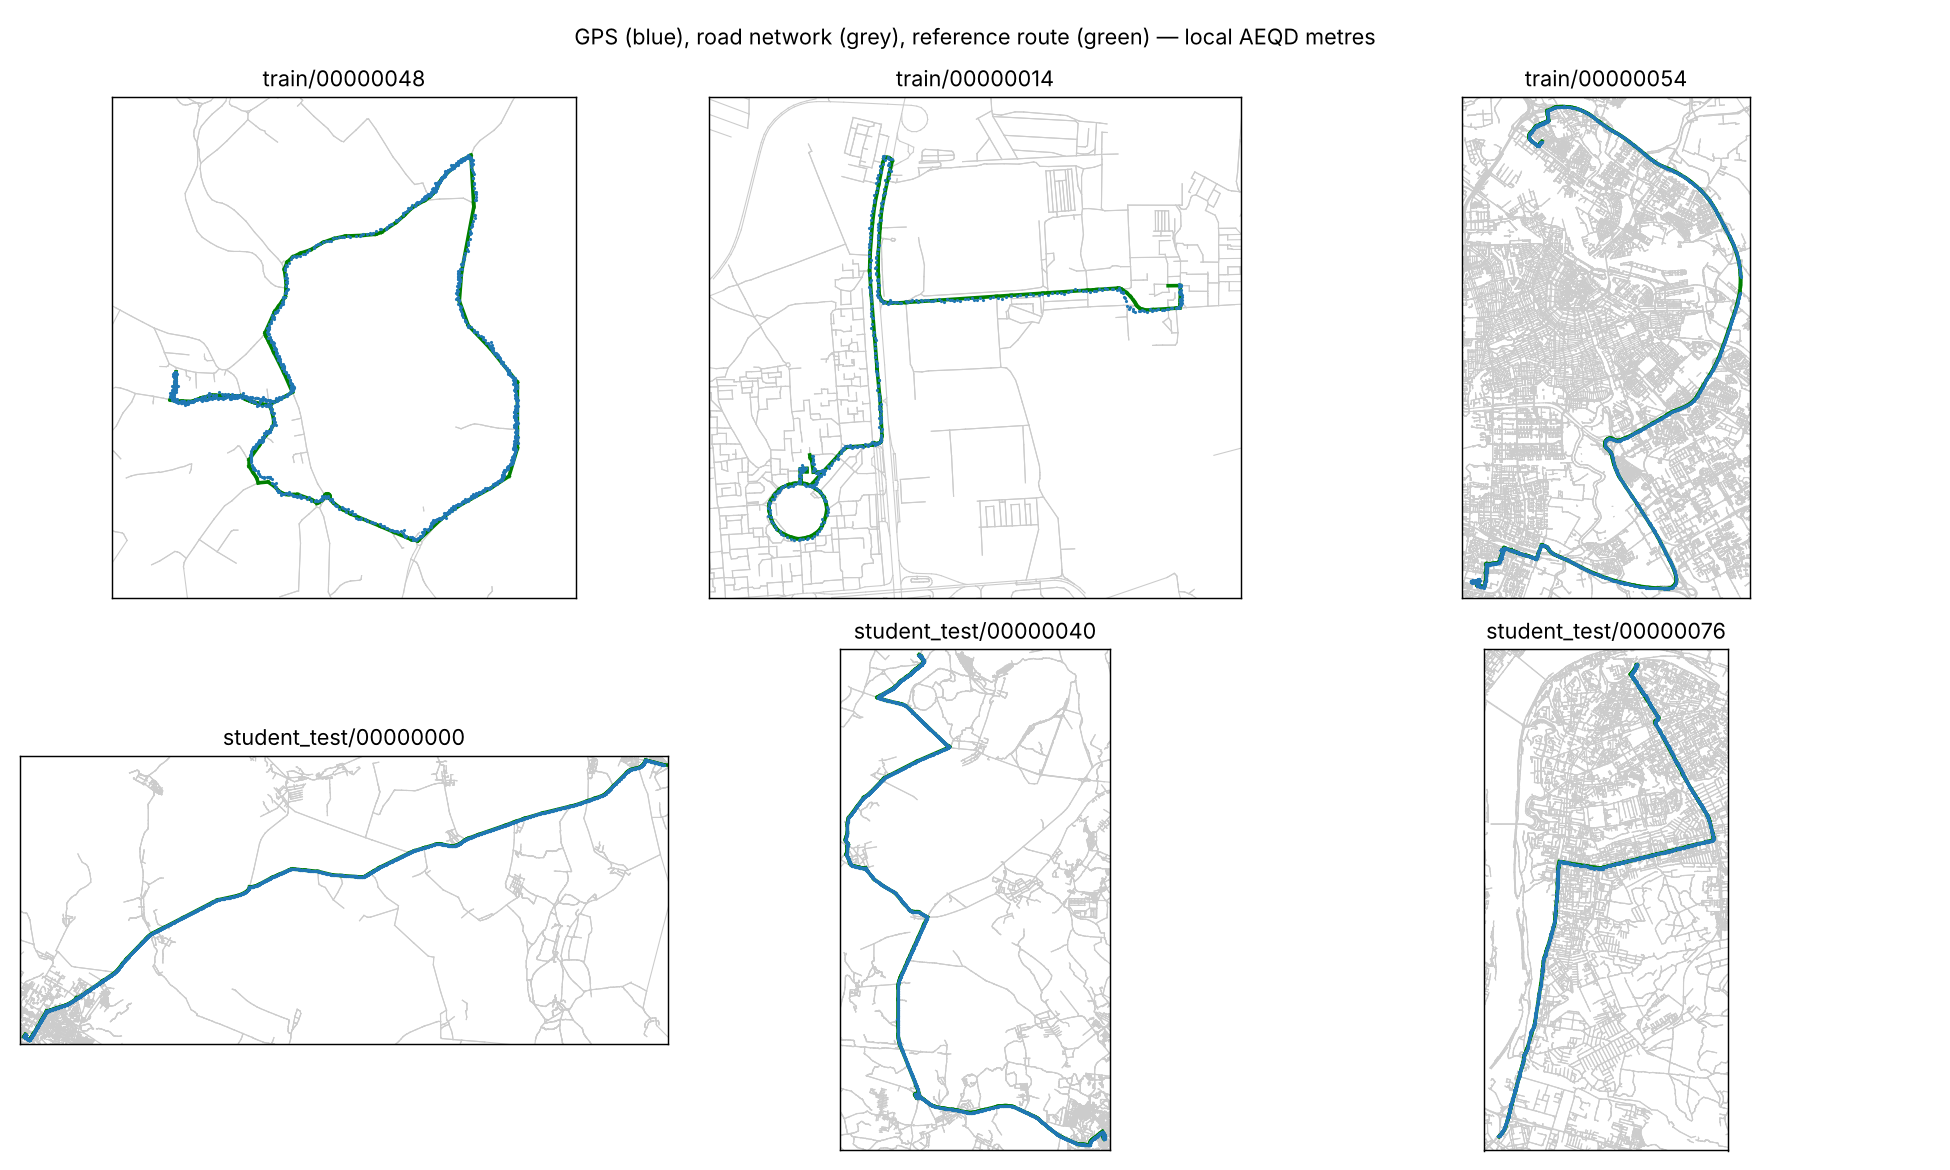

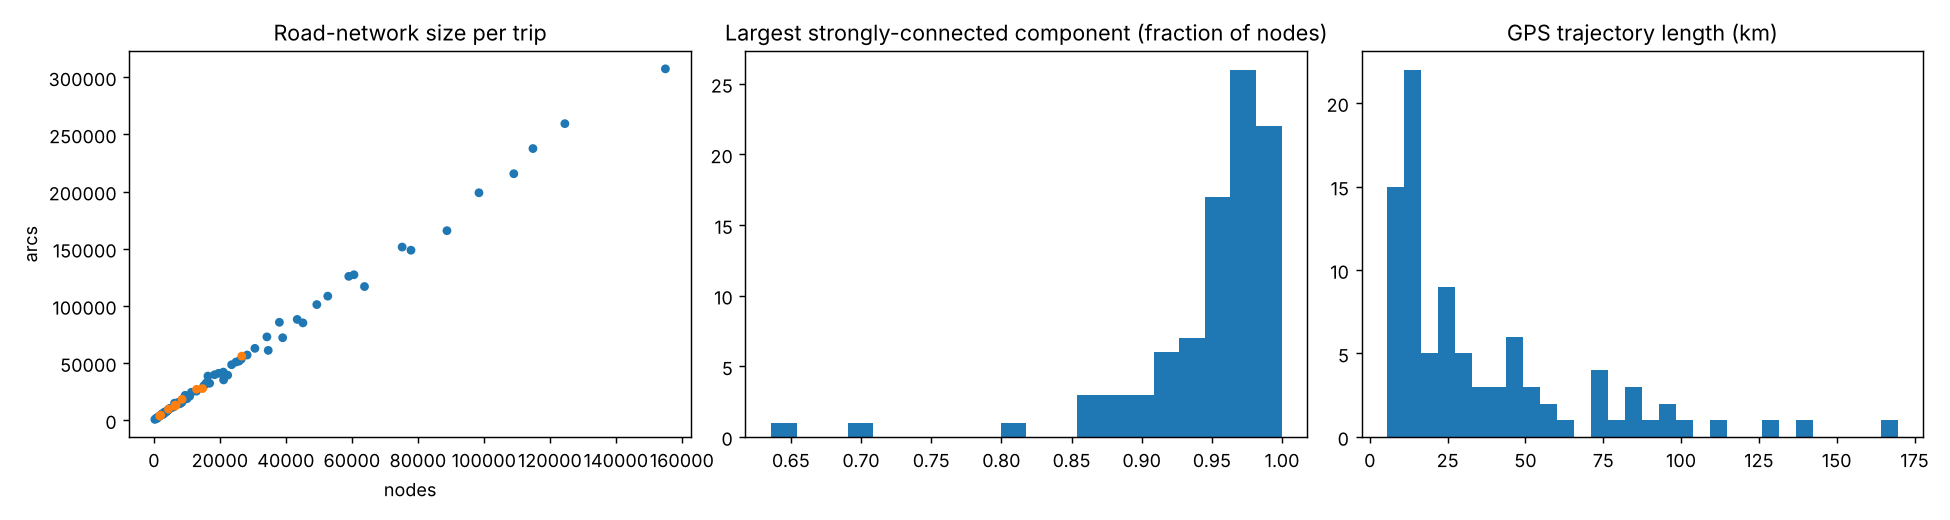

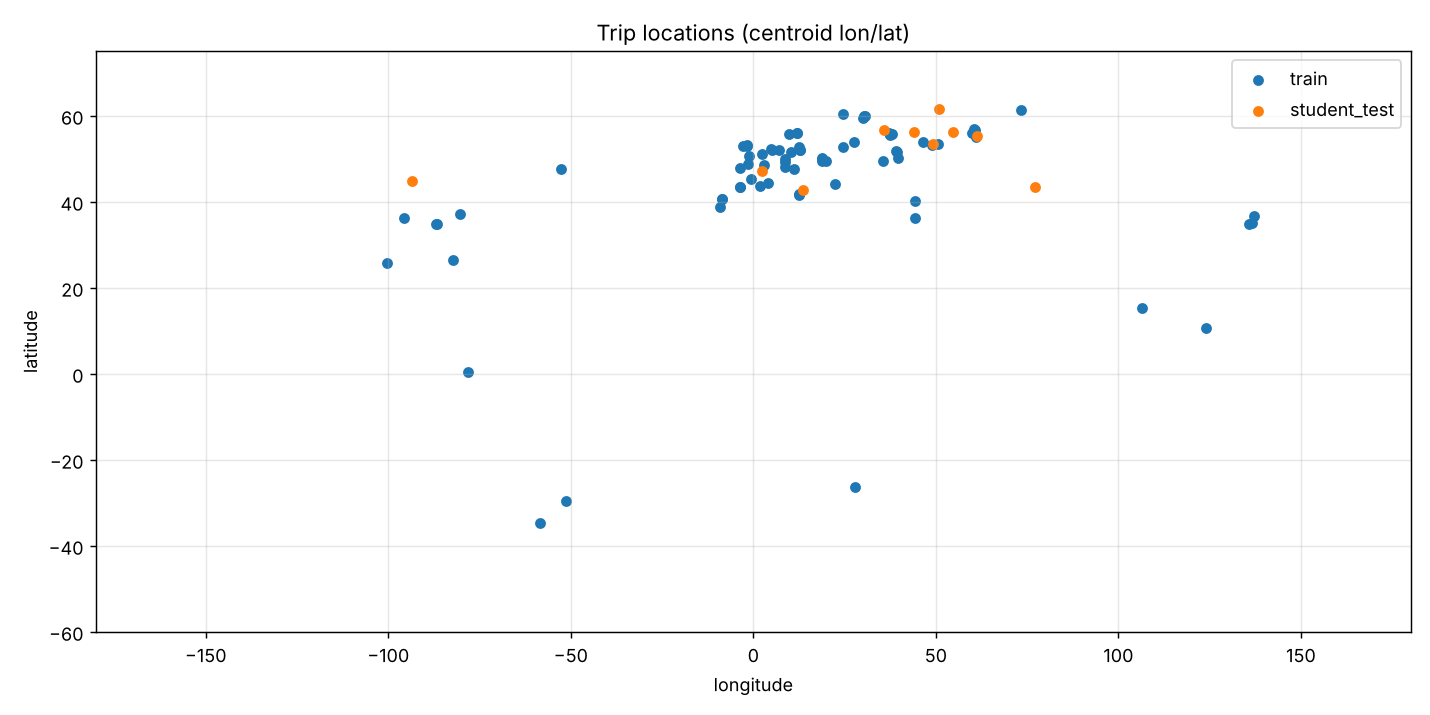

In [6]:
for f in ["eda_distributions.png", "eda_trajectories.png", "eda_network.png", "eda_trip_locations.png"]:
    display(Image(f"{FIG}/{f}", width=1000))

## 6. Folium map: GPS, road network and reference route (train trip 00000048)

In [7]:
import importlib; maps = importlib.import_module("06_maps")
f = maps.render_eda("train", "00000048"); print(f)
IFrame(os.path.relpath(f, os.path.join(ROOT, "notebooks")), width="100%", height=520)

/home/claude/pathsnap/results/maps/eda_train_00000048.html


**Observations.** Sampling is ~97% at 1 Hz. There are no NaNs or duplicate timestamps, but some long gaps exist (up to 153,064 s). Most roads are two-way, which gives pairs of opposite arcs. Trips 33 and 54 have a systematic ~120–140 m offset and are excluded from training. The data are spread around the world, so we use a per-trip local metric projection.